In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

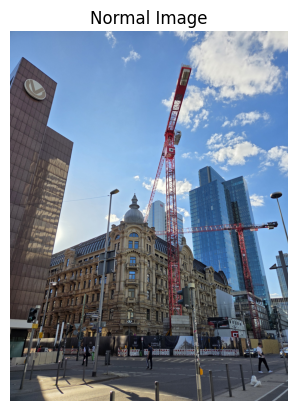

In [49]:
image = cv2.imread(r'C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\Frankfurt.jpg')
RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(RGB)
plt.title('Normal Image')
plt.axis('off')
plt.show()


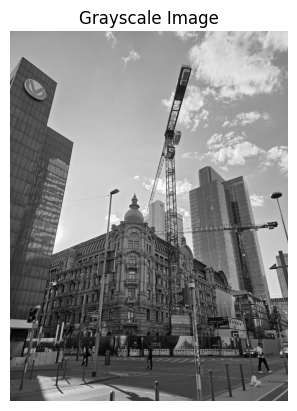

In [20]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

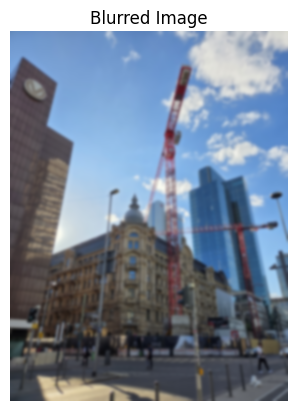

In [53]:
blurred = cv2.GaussianBlur(RGB, (0,0), 15)
plt.imshow(blurred, )
plt.title('Blurred Image')  
plt.axis('off')
plt.show()

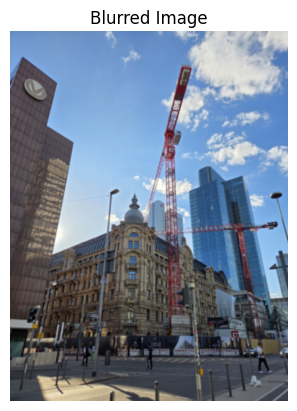

In [51]:
blurred = cv2.GaussianBlur(RGB, (0, 0), 5) # when ksize is (0, 0), sigmaX is used to calculate the kernel size
plt.imshow(blurred,)
plt.title('Blurred Image')  
plt.axis('off')
plt.show()

Text(0.5, 1.0, 'Lower Resolution Image')

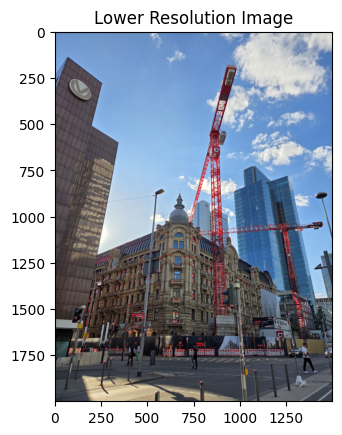

In [115]:
lower_res = cv2.pyrDown(RGB)
plt.imshow(lower_res)
plt.title('Lower Resolution Image')

Image 1 shape: (1000, 750, 3)


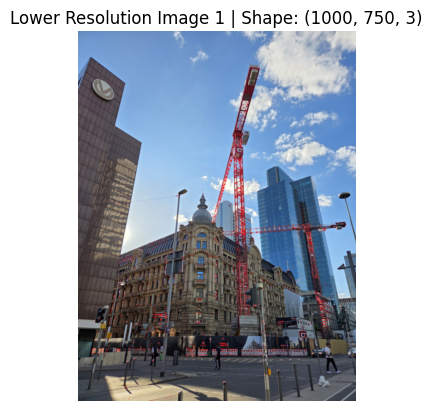

Image 2 shape: (500, 375, 3)


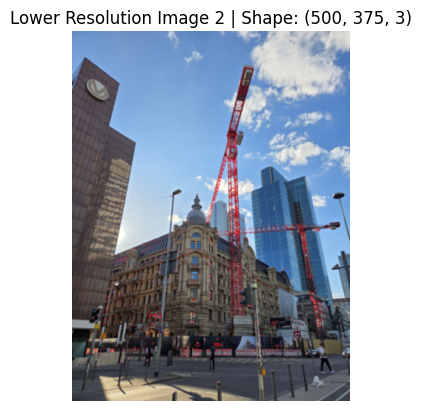

Image 3 shape: (250, 188, 3)


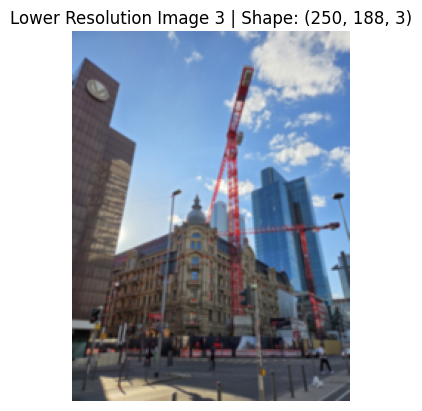

Image 4 shape: (125, 94, 3)


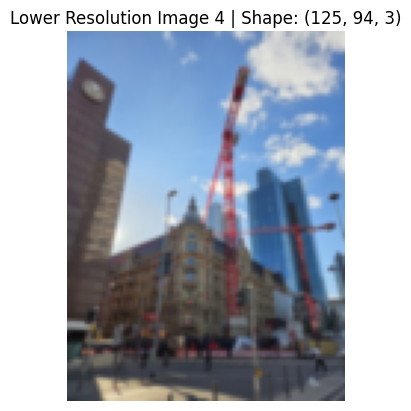

In [116]:
i = 0
for i in range(4):
    lower_res = cv2.pyrDown(lower_res)
    print(f"Image {i+1} shape: {lower_res.shape}")
    plt.imshow(lower_res)
    plt.title(f'Lower Resolution Image {i+1} | Shape: {lower_res.shape}')
    plt.axis('off')
    plt.show()
    # note that VS code is auto scaling the images to fit the display, so they may look similar in size, but they are actually getting smaller in resolution each time. You can check the shape of lower_res to see the actual resolution.

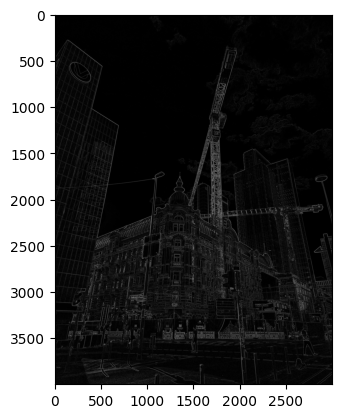

In [73]:
# sobel Filter 1
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
sobel = cv2.magnitude(sobel_x, sobel_y)
plt.imshow(sobel, cmap='gray')

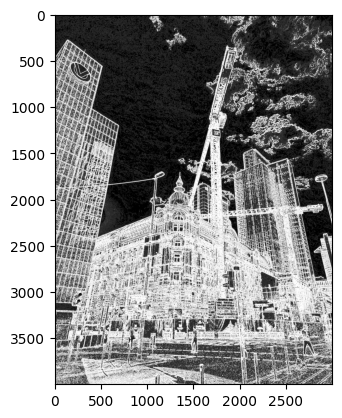

In [79]:
# Sobel Filter 2
low_threshold = 50
high_threshold = 370
edges= np.zeros_like(sobel)
edges[sobel > high_threshold] = 255
edges[(sobel >= low_threshold) & (sobel <= high_threshold)] = 50
plt.imshow(edges, cmap='gray')

Text(0.5, 1.0, 'Canny Edges')

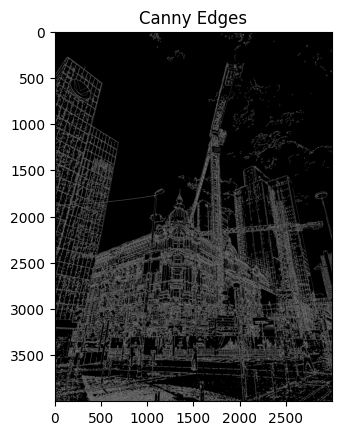

In [83]:
# Canny Edge Detection
edges_canny = cv2.Canny(gray, 50, 120) 
plt.imshow(edges_canny, cmap='gray')
plt.title('Canny Edges')

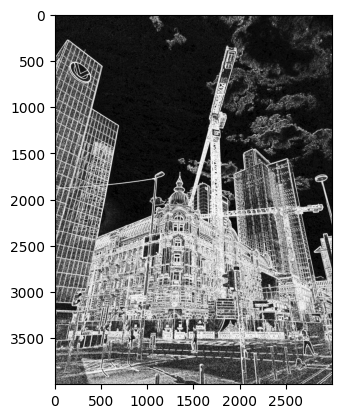

In [92]:
# Laplacian Filter
blurred_gray = cv2.GaussianBlur(gray, (5, 5), 0)
laplacian = cv2.Laplacian(blurred_gray, cv2.CV_64F, ksize=5) 
laplacian_abs = cv2.convertScaleAbs(laplacian)
plt.imshow(laplacian_abs, cmap='gray')


Text(0.5, 1.0, 'Scharr Filter')

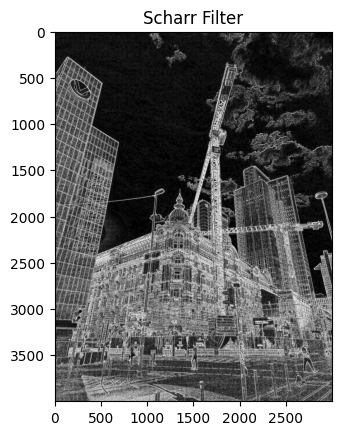

In [94]:
# Scharr Filter 
# Similar to Sobel, but with 'ksize=-1' which tells OpenCV to use Scharr
scharrx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=-1)
scharry = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=-1)
scharr_combined = cv2.addWeighted(cv2.convertScaleAbs(scharrx), 0.5, 
                                  cv2.convertScaleAbs(scharry), 0.5, 0)
plt.imshow(scharr_combined, cmap='gray')
plt.title('Scharr Filter')

Text(0.5, 1.0, 'Laplacian: Shifting from Edges to Blobs')

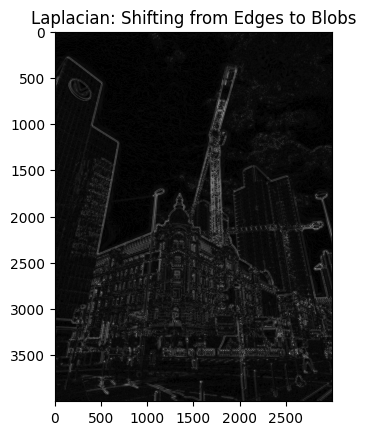

In [100]:
# Laplacian with larger blur to shift from edges to blobs
blob_blur = cv2.GaussianBlur(gray, (55, 55), 5) 
lap_blob = cv2.Laplacian(blob_blur, cv2.CV_64F, ksize= 5)
lap_blob = cv2.convertScaleAbs(lap_blob)

plt.imshow(lap_blob, cmap='gray')
plt.title('Laplacian: Shifting from Edges to Blobs')

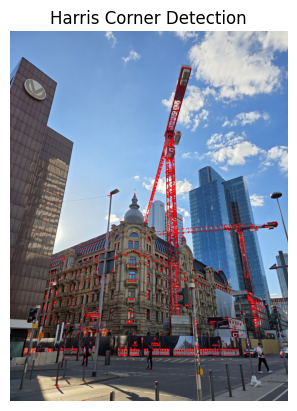

In [108]:
# Harris Corner Detection
gray_float = np.float32(gray)
dst = cv2.cornerHarris(gray_float, blockSize=5, ksize= 5, k=0.09)
dst = cv2.dilate(dst, None)
image_with_corners = RGB.copy() 
image_with_corners[dst > 0.01 * dst.max()] = [255, 0, 0] # Mark corners in Red

plt.imshow(image_with_corners)
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()

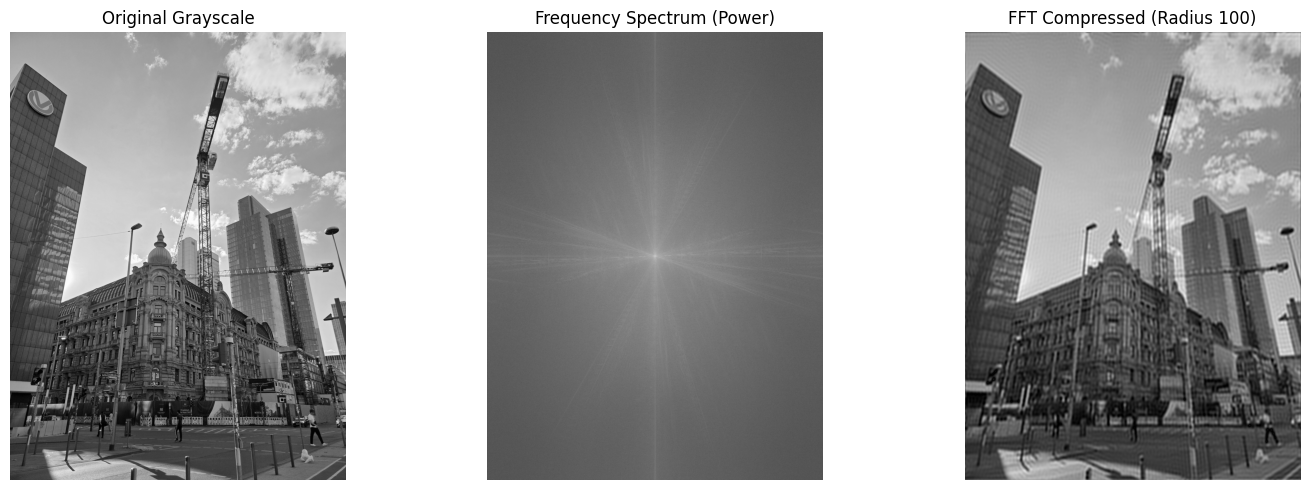

We only kept 0.26% of the frequency data!


In [ ]:
# Extra: FFT Compression (with help from Gemini)
f_transform = np.fft.fft2(gray)
f_shift = np.fft.fftshift(f_transform) # Shift zero frequency to center

# 3. Create a Low Pass Filter (Compression) Mask
rows, cols = gray.shape # Now this works because gray.shape is only (rows, cols)
crow, ccol = rows//2, cols//2
mask = np.zeros((rows, cols), np.uint8)
radius = 100  # Smaller radius = higher compression (more data lost)
cv2.circle(mask, (ccol, crow), radius, 1, -1)

# 4. Apply mask and transform back (Inverse FFT)
f_shift_compressed = f_shift * mask
f_ishift = np.fft.ifftshift(f_shift_compressed)
img_compressed = np.abs(np.fft.ifft2(f_ishift))

# 5. Visualize the Power Spectrum and the Result
magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1) # +1 to avoid log(0)

plt.figure(figsize=(15, 5))

# Plot 1: Original (Use 'gray' here instead of 'img')
plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray') 
plt.title('Original Grayscale')
plt.axis('off')

# Plot 2: Spectrum
plt.subplot(1, 3, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Frequency Spectrum (Power)')
plt.axis('off')

# Plot 3: Result
plt.subplot(1, 3, 3)
plt.imshow(img_compressed, cmap='gray')
plt.title(f'FFT Compressed (Radius {radius})')
plt.axis('off')

plt.tight_layout()
plt.show()

# Show the 'Compression' ratio
keep_percent = (np.sum(mask) / (rows * cols)) * 100
print(f"We only kept {keep_percent:.2f}% of the frequency data!")